In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from geopy.distance import geodesic

In [7]:
data = pd.read_excel("anomalies_corrected_data.xlsx", sheet_name="Data")
data_dist = data.copy()
print(data["step"])

0            1
1            2
2            3
3            4
4            5
         ...  
15870    15871
15871    15872
15872    15873
15873    15874
15874    15875
Name: step, Length: 15875, dtype: int64


In [22]:
data["distances"] = [geodesic(
        (data["latitude"].iloc[i], data["longitude"].iloc[i]),
        (data["latitude"].iloc[i+1], data["longitude"].iloc[i+1])
        ).km for i in range(len(data)-1)] + [None] #plus None because the comparision shirnks the data into len(data)-1

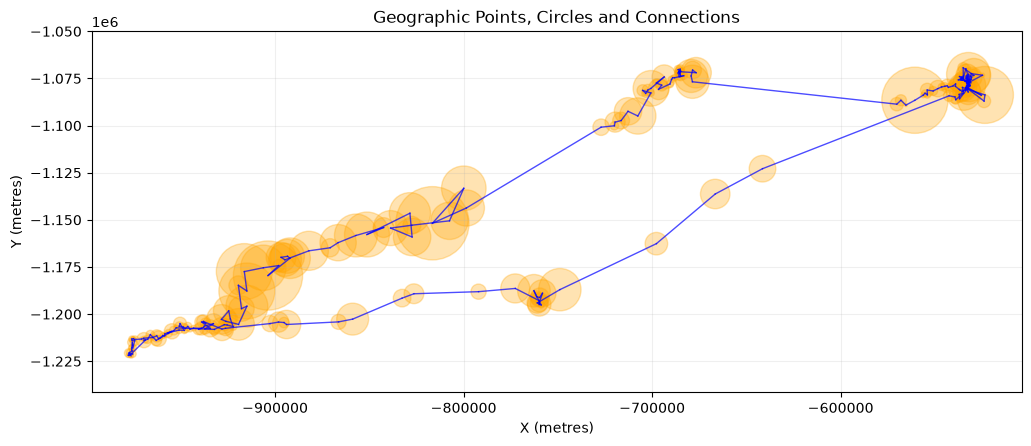

In [ ]:

from pyproj import Transformer
import matplotlib.pyplot as plt
import random

# 1. Select unique geographic locations
sub_data = data.drop_duplicates(subset=["latitude", "longitude"]).head(600)

latitude = sub_data["latitude"]
longitude = sub_data["longitude"]
outer_radius = sub_data["outer_radius"]

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5514", always_xy=True)

x_vals, y_vals = transformer.transform(longitude.to_numpy(), latitude.to_numpy())

# 4. Create figure
fig, ax = plt.subplots(figsize=(12, 10))

# 5. Draw circles around all points
for i in range(len(sub_data)-1):

    x, y, r = x_vals[i], y_vals[i], outer_radius.iloc[i]

    x_next, y_next, r_next = x_vals[i+1], y_vals[i+1], outer_radius.iloc[i+1]

    circle = plt.Circle(
        (x, y),
        radius=r,
        facecolor="orange",
        alpha=0.3,
        edgecolor="orange"
    )

    ax.add_patch(circle)

    ax.plot(
        [x, x_next],
        [y, y_next],
        color="blue",
        linewidth=1,
        alpha=0.7,
        zorder=2
    )


# 8. Configure plot boundaries
max_radius = outer_radius.max()

ax.set_xlim(min(x_vals) - max_radius, max(x_vals) + max_radius)

ax.set_ylim(min(y_vals) - max_radius, max(y_vals) + max_radius)

ax.set_aspect("equal")
ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_title("Geographic Points, Circles and Connections")
ax.grid(alpha=0.2)

plt.show()


In [24]:
#drop the last line - contains None
data = data[:-1].copy()
print(data["distances"].value_counts())


distances
0.000000     14212
0.544123        43
0.771487        37
2.081843        32
1.061901        28
             ...  
1.290572         1
26.990212        1
31.929992        1
3.185369         1
2.587214         1
Name: count, Length: 467, dtype: int64


(array([571., 377., 234., 119.,  75.,  47.,  20.,  14.,  27.,  27.,   8.,
         29.,  17.,   1.,   2.,   0.,   2.,   1.,   6.,   6.,   0.,   1.,
          0.,   3.,   4.,   1.,   7.,   0.,   1.,   0.,   1.,   0.,   3.,
          0.,   2.,   0.,   0.,   0.,   3.,   0.,   0.,   0.,   0.,   0.,
          0.,  25.,   0.,  13.,   0.,   0.,   0.,   0.,   0.,   3.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   3.,   0.,   0.,   3.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 

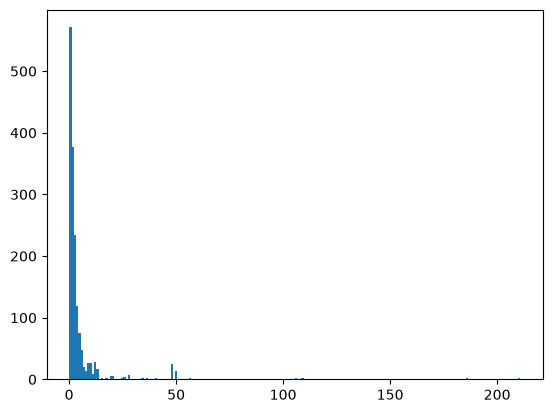

In [32]:
sub_data = data[data["distances"] != 0]
plt.hist(sub_data["distances"], bins=200)